In [ ]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import nltk

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer
print("Setup complete ✅")

Setup complete ✅


In [ ]:
corpus = {
    "symptoms": [
        "what are the early signs of diabetes",
        "why do i feel very thirsty and urinate frequently",
        "is blurry vision a symptom of high blood sugar",
        "what are the symptoms of type 2 diabetes",
        "i am always tired and losing weight without trying could it be diabetes",
        "what does hyperglycemia feel like",
        "what are the signs of low blood sugar",
        "do tingling feet mean diabetes",
        "are slow healing wounds linked to diabetes",
        "how do i know if my child has type 1 diabetes",
        "what are the warning signs of high blood sugar",
        "i feel extremely hungry even after eating is it diabetes",
        "what symptoms do diabetic people have",
        "my vision is blurry and i am always thirsty",
        "what are the symptoms of type 1 diabetes in kids",
        "signs of prediabetes to look out for",
        "why do my hands and feet feel numb with diabetes",
        "what are the symptoms of hypoglycemia",
        "frequent urination at night is it a sign of sugar",
        "how can i tell if i have diabetes",
    ],
    "diet_nutrition": [
        "what foods should i eat with diabetes",
        "can diabetics eat rice",
        "which fruits are safe for diabetes patients",
        "what is a good diabetic meal plan",
        "is sugar completely banned for diabetics",
        "how many carbohydrates should i have per meal",
        "what is the glycemic index of foods",
        "can i drink fruit juice if i have diabetes",
        "are sweet potatoes good for blood sugar",
        "what snacks are healthy for diabetes",
        "which foods should a diabetic avoid",
        "is brown rice better than white rice for diabetes",
        "can diabetic patients eat mangoes",
        "what should i eat for breakfast if i have diabetes",
        "are sweets allowed for diabetes patients",
        "what is the best diet for type 2 diabetes",
        "can i eat chapati and dal with diabetes",
        "low glycemic index foods for blood sugar control",
        "is milk good for diabetic people",
        "how to plan meals for diabetes",
    ],
    "medication_insulin": [
        "how does metformin work",
        "what are the side effects of metformin",
        "when should i take insulin",
        "what are the different types of insulin",
        "how do i inject insulin properly",
        "do i need insulin for type 2 diabetes",
        "can i stop taking my diabetes tablets",
        "how should i store insulin",
        "what happens if i miss a dose of my diabetes medicine",
        "what are the oral medications for diabetes",
        "what are the side effects of insulin",
        "how long does insulin take to work",
        "which tablets are used for type 2 diabetes",
        "should metformin be taken before or after food",
        "can i take insulin and metformin together",
        "what is basal and bolus insulin",
        "where on the body should i inject insulin",
        "is insulin addictive for diabetes patients",
        "what is the best medicine for diabetes",
        "how to use an insulin pen",
    ],
    "glucose_monitoring": [
        "how often should i check my blood sugar",
        "what is a normal fasting blood glucose level",
        "what is the hba1c test",
        "how do i use a glucometer",
        "what should my blood sugar be after eating",
        "what is a continuous glucose monitor",
        "when is the best time to test glucose at home",
        "what does an hba1c of 7 mean",
        "how do i prepare for a fasting glucose test",
        "what is the target blood sugar range for diabetics",
        "what is a normal blood sugar level",
        "how do i read my glucometer result",
        "how often should hba1c be tested",
        "what is the normal range of postprandial sugar",
        "what number should my glucose reading be before breakfast",
        "which test confirms diabetes",
        "what is ogtt glucose tolerance test",
        "how many times a day should i test my sugar",
        "what is a good hba1c for a diabetic",
        "do i need to fast before checking blood glucose",
    ],
    "exercise_lifestyle": [
        "what exercises are good for diabetes",
        "how much exercise should a diabetic do per week",
        "can walking lower blood sugar",
        "does stress affect blood sugar levels",
        "how does sleep affect diabetes",
        "can i lose weight to reverse type 2 diabetes",
        "is yoga helpful for diabetes",
        "does smoking affect diabetes",
        "should i exercise when my sugar is high",
        "how does alcohol affect blood sugar",
        "is walking good for diabetes",
        "does going for a jog help control sugar",
        "how can i lower blood sugar naturally with exercise",
        "can yoga and meditation control diabetes",
        "how much weight should i lose to control diabetes",
        "is it safe to workout at the gym with diabetes",
        "does lack of sleep raise blood sugar",
        "can i drink alcohol if i am diabetic",
        "what lifestyle changes help manage type 2 diabetes",
        "does cycling or swimming help diabetes",
    ],
    "complications_prevention": [
        "how does diabetes affect the kidneys",
        "can diabetes cause blindness",
        "what is diabetic neuropathy",
        "how can i prevent diabetic foot ulcers",
        "does diabetes increase the risk of heart disease",
        "how often should diabetics get eye exams",
        "what is diabetic retinopathy",
        "how to prevent long term complications of diabetes",
        "can diabetes damage nerves",
        "how do i take care of my feet if i have diabetes",
        "how can diabetes harm my eyes",
        "what are the long term effects of diabetes",
        "can diabetes lead to kidney failure",
        "why do diabetics get foot wounds that do not heal",
        "how to protect my kidneys if i have diabetes",
        "can high blood sugar cause a stroke or heart attack",
        "what is diabetic nephropathy",
        "how do i prevent diabetes complications",
        "can diabetes cause amputation",
        "how often should i get my feet and kidneys checked",
    ],
    "emergency": [
        "my blood sugar is very low and i feel confused",
        "someone with diabetes has passed out",
        "i am vomiting and have fruity smelling breath with high sugar",
        "my diabetic father is unconscious",
        "i have severe chest pain and my sugar is high",
        "my blood sugar is 500 and i cannot stop vomiting",
        "i am having a seizure and i have diabetes",
        "diabetic emergency please help",
        "i feel faint shaky and sweating and my sugar is 40",
        "difficulty breathing and extreme thirst with high glucose",
        "my diabetic mother is unconscious",
        "my sugar is very low and i am fainting",
        "diabetic patient not responding help",
        "i have diabetes and i am having a seizure",
        "my glucose is 600 and i feel very sick",
        "my child with diabetes passed out",
        "i am sweating shaking and about to collapse with low sugar",
        "ketoacidosis emergency what do i do",
        "diabetic coma what to do right now",
        "i cannot breathe properly and my sugar is very high",
    ],
}

df = pd.DataFrame([(q, intent) for intent, qs in corpus.items() for q in qs],
                  columns=["query", "intent"])
print("Total queries:", len(df), "| Intents:", df.intent.nunique())
df.intent.value_counts()

Total queries: 140 | Intents: 7


,count
intent,
symptoms,20
diet_nutrition,20
medication_insulin,20
glucose_monitoring,20
exercise_lifestyle,20
complications_prevention,20
emergency,20


In [ ]:
taxonomy = {
    "Diabetes Basics": {
        "Types of Diabetes": ["Type 1", "Type 2", "Gestational"],
        "Symptoms & Diagnosis": ["symptoms"],
    },
    "Nutrition & Lifestyle": {
        "Diet & Meal Planning": ["diet_nutrition"],
        "Physical Activity & Habits": ["exercise_lifestyle"],
    },
    "Treatment & Monitoring": {
        "Medications & Insulin": ["medication_insulin"],
        "Glucose Monitoring & Tests": ["glucose_monitoring"],
    },
    "Complications & Emergencies": {
        "Long-term Complications": ["complications_prevention"],
        "Acute Emergencies": ["emergency"],
    },
}

def print_taxonomy(t):
    for major, subs in t.items():
        print(f"📁 {major}")
        for sub, items in subs.items():
            print(f"   └── {sub}  →  {items}")
print_taxonomy(taxonomy)

# intent -> (major category, subcategory)
intent_to_taxonomy = {i: (m, s) for m, subs in taxonomy.items()
                      for s, items in subs.items() for i in items}

📁 Diabetes Basics
   └── Types of Diabetes  →  ['Type 1', 'Type 2', 'Gestational']
   └── Symptoms & Diagnosis  →  ['symptoms']
📁 Nutrition & Lifestyle
   └── Diet & Meal Planning  →  ['diet_nutrition']
   └── Physical Activity & Habits  →  ['exercise_lifestyle']
📁 Treatment & Monitoring
   └── Medications & Insulin  →  ['medication_insulin']
   └── Glucose Monitoring & Tests  →  ['glucose_monitoring']
📁 Complications & Emergencies
   └── Long-term Complications  →  ['complications_prevention']
   └── Acute Emergencies  →  ['emergency']


12 concepts, 15 relationships


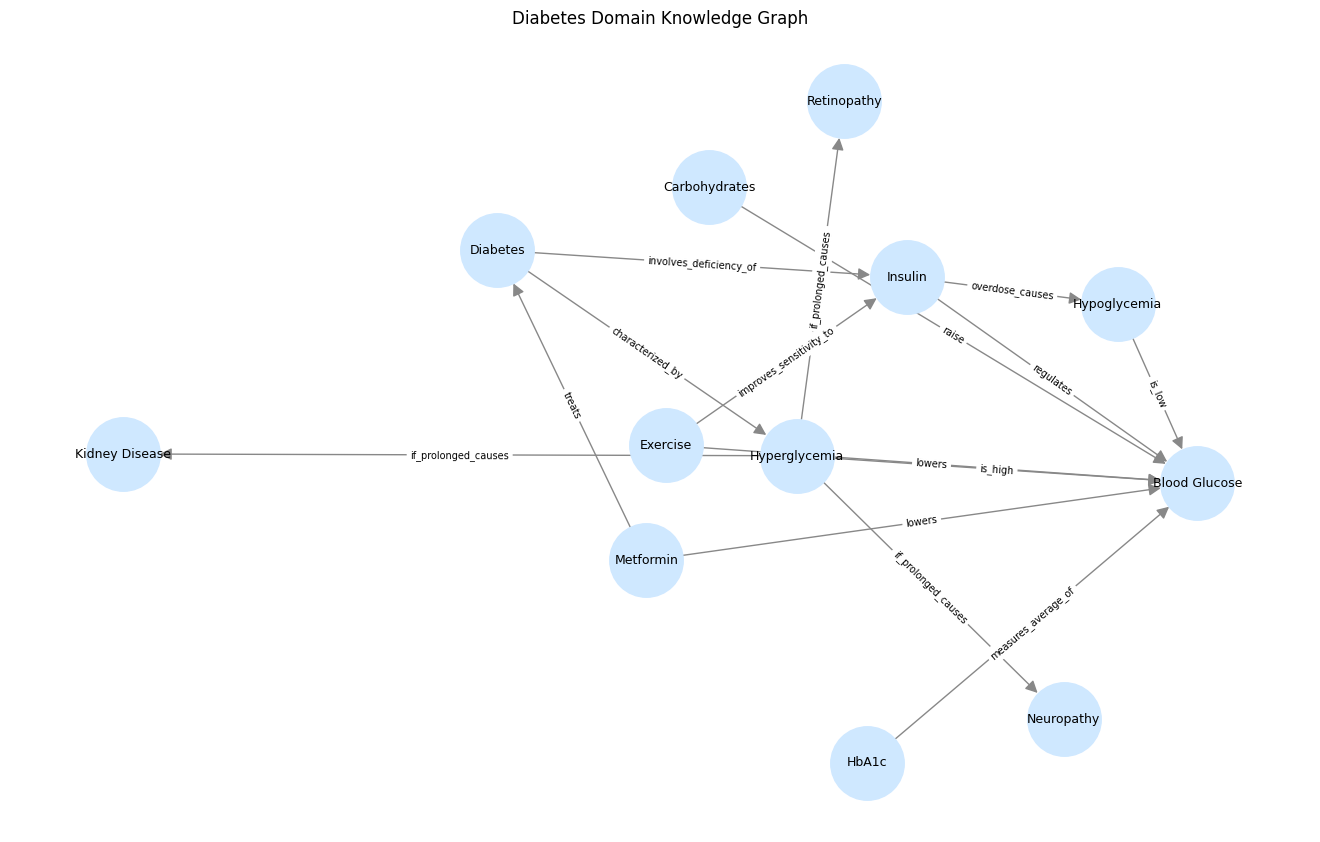


Facts about 'Blood Glucose':
  • Insulin --regulates--> Blood Glucose
  • Metformin --lowers--> Blood Glucose
  • HbA1c --measures_average_of--> Blood Glucose
  • Carbohydrates --raise--> Blood Glucose
  • Exercise --lowers--> Blood Glucose
  • Hypoglycemia --is_low--> Blood Glucose
  • Hyperglycemia --is_high--> Blood Glucose


In [ ]:
concepts = ["Diabetes", "Insulin", "Blood Glucose", "HbA1c", "Hyperglycemia", "Hypoglycemia",
            "Metformin", "Carbohydrates", "Exercise", "Neuropathy", "Retinopathy", "Kidney Disease"]

relationships = [
    ("Diabetes", "characterized_by", "Hyperglycemia"),
    ("Insulin", "regulates", "Blood Glucose"),
    ("Diabetes", "involves_deficiency_of", "Insulin"),
    ("Metformin", "treats", "Diabetes"),
    ("Metformin", "lowers", "Blood Glucose"),
    ("HbA1c", "measures_average_of", "Blood Glucose"),
    ("Carbohydrates", "raise", "Blood Glucose"),
    ("Exercise", "improves_sensitivity_to", "Insulin"),
    ("Exercise", "lowers", "Blood Glucose"),
    ("Insulin", "overdose_causes", "Hypoglycemia"),
    ("Hyperglycemia", "if_prolonged_causes", "Neuropathy"),
    ("Hyperglycemia", "if_prolonged_causes", "Retinopathy"),
    ("Hyperglycemia", "if_prolonged_causes", "Kidney Disease"),
    ("Hypoglycemia", "is_low", "Blood Glucose"),
    ("Hyperglycemia", "is_high", "Blood Glucose"),
]
print(f"{len(concepts)} concepts, {len(relationships)} relationships")

G = nx.DiGraph()
G.add_nodes_from(concepts)
for s, r, o in relationships:
    G.add_edge(s, o, label=r)

plt.figure(figsize=(13, 8))
pos = nx.spring_layout(G, seed=7, k=1.4)
nx.draw(G, pos, with_labels=True, node_color="#cfe8ff", node_size=2800,
        font_size=9, arrowsize=18, edge_color="#888")
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), font_size=7)
plt.title("Diabetes Domain Knowledge Graph")
plt.show()

def related(concept):
    return [f"{s} --{r}--> {o}" for s, r, o in relationships if concept in (s, o)]

print("\nFacts about 'Blood Glucose':")
for f in related("Blood Glucose"): print("  •", f)

In [ ]:
tokenizer = RegexpTokenizer(r"[a-z0-9]+")
lemmatizer = WordNetLemmatizer()
STOP = set(stopwords.words("english"))

def preprocess(text, return_tokens=False):
    text = text.lower()                                    # 1. lowercase
    tokens = tokenizer.tokenize(text)                      # 2. tokenize
    tokens = [t for t in tokens if t not in STOP]          # 3. stopword removal
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n")
              for t in tokens]                             # 4. lemmatize
    return tokens if return_tokens else " ".join(tokens)

demo = "What are the Side Effects of taking Metformin for Diabetics?"
print("Original :", demo)
print("Lowercase:", demo.lower())
print("Tokens   :", tokenizer.tokenize(demo.lower()))
print("No stops :", [t for t in tokenizer.tokenize(demo.lower()) if t not in STOP])
print("Lemmas   :", preprocess(demo, return_tokens=True))

df["clean"] = df["query"].apply(preprocess)
df.head()

Original : What are the Side Effects of taking Metformin for Diabetics?
Lowercase: what are the side effects of taking metformin for diabetics?
Tokens   : ['what', 'are', 'the', 'side', 'effects', 'of', 'taking', 'metformin', 'for', 'diabetics']
No stops : ['side', 'effects', 'taking', 'metformin', 'diabetics']
Lemmas   : ['side', 'effect', 'take', 'metformin', 'diabetic']


,query,intent,clean
0,what are the early signs of diabetes,symptoms,early sign diabetes
1,why do i feel very thirsty and urinate frequently,symptoms,feel thirsty urinate frequently
2,is blurry vision a symptom of high blood sugar,symptoms,blurry vision symptom high blood sugar
3,what are the symptoms of type 2 diabetes,symptoms,symptom type 2 diabetes
4,i am always tired and losing weight without tr...,symptoms,always tire lose weight without try could diab...


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=42)
print("Train:", len(X_train), "| Test:", len(X_test))

def make_pipe(clf):
    # TF-IDF on word 1-2 grams + character n-grams
    tfidf = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True)),
    ])
    return Pipeline([("tfidf", tfidf), ("clf", clf)])

candidates = {
    "Naive Bayes":         make_pipe(MultinomialNB(alpha=0.1)),
    "Logistic Regression": make_pipe(LogisticRegression(C=20, max_iter=2000)),
    "Linear SVM":          make_pipe(LinearSVC(C=1.0)),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, df["clean"], df["intent"], cv=skf, scoring="accuracy")
    print(f"{name:22s} CV accuracy = {scores.mean():.3f} ± {scores.std():.3f}")

# Logistic Regression is used: it gives probabilities = confidence score for the low-confidence rule
model = candidates["Logistic Regression"]
model.fit(X_train, y_train)

Train: 105 | Test: 35
Naive Bayes            CV accuracy = 0.821 ± 0.060
Logistic Regression    CV accuracy = 0.786 ± 0.078
Linear SVM             CV accuracy = 0.771 ± 0.066


Pipeline(steps=[('tfidf',
                 FeatureUnion(transformer_list=[('word',
                                                 TfidfVectorizer(ngram_range=(1,
                                                                              2),
                                                                 sublinear_tf=True)),
                                                ('char',
                                                 TfidfVectorizer(analyzer='char_wb',
                                                                 ngram_range=(2,
                                                                              4),
                                                                 sublinear_tf=True))])),
                ('clf', LogisticRegression(C=20, max_iter=2000))])

Accuracy : 0.771
Precision: 0.836 (macro)
Recall   : 0.771 (macro)
F1-score : 0.764 (macro)

                          precision    recall  f1-score   support

complications_prevention       0.62      1.00      0.77         5
          diet_nutrition       1.00      0.80      0.89         5
               emergency       1.00      1.00      1.00         5
      exercise_lifestyle       0.60      0.60      0.60         5
      glucose_monitoring       0.62      1.00      0.77         5
      medication_insulin       1.00      0.60      0.75         5
                symptoms       1.00      0.40      0.57         5

                accuracy                           0.77        35
               macro avg       0.84      0.77      0.76        35
            weighted avg       0.84      0.77      0.76        35



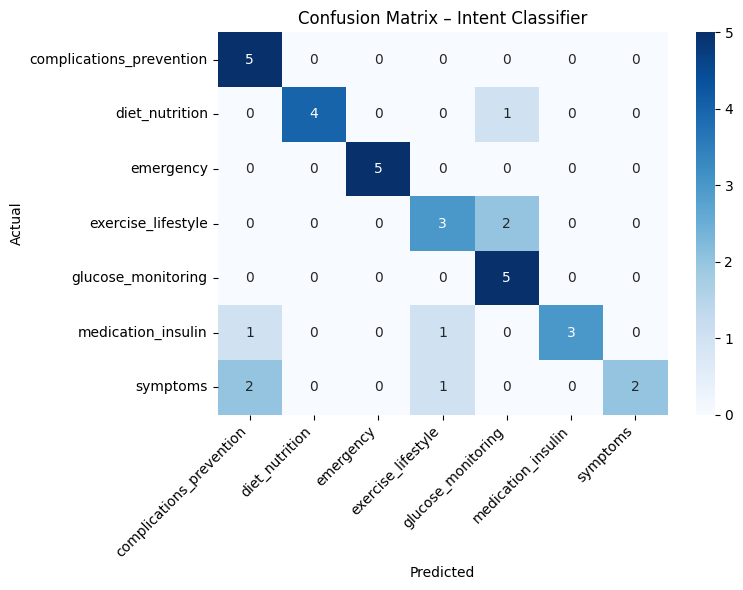

In [ ]:
y_pred = model.predict(X_test)
labels = sorted(df.intent.unique())

acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
print(f"Accuracy : {acc:.3f}")
print(f"Precision: {p:.3f} (macro)")
print(f"Recall   : {r:.3f} (macro)")
print(f"F1-score : {f1:.3f} (macro)\n")
print(classification_report(y_test, y_pred, labels=labels, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix – Intent Classifier")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

In [ ]:
DISCLAIMER = "ℹ️ This is general information, not medical advice. Please consult your doctor or diabetes care team."

knowledge_base = {
    "symptoms": {
        "title": "Symptoms of Diabetes",
        "points": [
            "Common signs: increased thirst, frequent urination, increased hunger, unexplained weight loss, fatigue, blurred vision.",
            "Other signs: slow-healing cuts or sores, frequent infections, tingling or numbness in hands/feet, dark skin patches (acanthosis nigricans).",
            "Type 1 tends to appear quickly (often in children/young adults); Type 2 develops gradually and may have no symptoms for years.",
            "Low blood sugar (<70 mg/dL) causes shakiness, sweating, hunger, dizziness and confusion; high blood sugar causes thirst, urination and fatigue.",
            "Diabetes is diagnosed only by blood tests (fasting glucose, HbA1c, OGTT). See a doctor if you have these symptoms.",
        ]},
    "diet_nutrition": {
        "title": "Diet & Nutrition",
        "points": [
            "Use the 'plate method': ½ non-starchy vegetables, ¼ lean protein, ¼ high-fibre carbohydrates.",
            "Prefer whole grains (brown rice, oats, millets, whole wheat), legumes, nuts, vegetables and low-GI fruits (apple, guava, berries) in portions.",
            "Rice and bread are allowed in controlled portions; pair them with protein/fibre and avoid large servings at once.",
            "Limit sugary drinks, fruit juice, sweets, refined flour and deep-fried foods. Don't skip meals.",
            "Carbohydrate needs are individual – a dietitian can set per-meal targets for you.",
        ]},
    "medication_insulin": {
        "title": "Medications & Insulin",
        "points": [
            "Metformin (usually first-line for Type 2) reduces glucose production by the liver and improves insulin sensitivity. Common side effects: nausea, diarrhoea, stomach upset (take with meals); rarely vitamin B12 deficiency.",
            "Other oral drug classes: sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors; GLP-1 injections are also used.",
            "Insulin types: rapid-acting, short-acting, intermediate, long-acting and premixed. Type 1 always needs insulin; some people with Type 2 need it too.",
            "Rotate injection sites (abdomen, thigh, upper arm). Store unopened insulin in the fridge; the in-use pen/vial is kept at room temperature as per the label.",
            "Missed a dose? Follow your prescriber's/pharmacist's instructions – never double up on your own. Never stop medicines without asking your doctor.",
        ]},
    "glucose_monitoring": {
        "title": "Blood Glucose Monitoring & Tests",
        "points": [
            "Normal fasting glucose: <100 mg/dL; prediabetes: 100–125; diabetes: ≥126 mg/dL.",
            "Typical targets for many adults with diabetes: 80–130 mg/dL before meals and <180 mg/dL 1–2 hours after a meal (your doctor may personalise this).",
            "HbA1c reflects the average glucose over ~3 months: <5.7% normal, 5.7–6.4% prediabetes, ≥6.5% diabetes; many adults aim for <7%.",
            "How often to test depends on treatment: people on insulin test several times a day; others as advised. Useful times: fasting, before meals, 2 h after meals, bedtime.",
            "Glucometer tips: wash and dry hands, use a fresh strip and lancet, apply a good blood drop, record the results. CGMs measure glucose continuously through a sensor.",
        ]},
    "exercise_lifestyle": {
        "title": "Exercise & Lifestyle",
        "points": [
            "Aim for at least 150 minutes/week of moderate aerobic activity (brisk walking, cycling, swimming) plus resistance training 2–3 days/week.",
            "A 10–15 minute walk after meals helps lower post-meal glucose. Yoga and stretching can help with stress and flexibility.",
            "Check glucose before/after exercise; carry fast-acting carbs if you use insulin or sulfonylureas (risk of low sugar). Avoid vigorous exercise if you have ketones or feel unwell.",
            "Losing 5–10% of body weight can substantially improve Type 2 control; some people achieve remission with sustained weight loss.",
            "Poor sleep, chronic stress, smoking and excess alcohol all worsen glucose control – aim for 7–9 hours of sleep and avoid tobacco.",
        ]},
    "complications_prevention": {
        "title": "Complications & Prevention",
        "points": [
            "Long-term high glucose can damage small vessels and nerves: retinopathy (eyes), nephropathy (kidneys), neuropathy (nerves), plus raise the risk of heart disease and stroke.",
            "Prevent them with good control (HbA1c, blood pressure, cholesterol), not smoking, and regular screening.",
            "Eyes: dilated eye exam at least once a year. Kidneys: urine albumin and eGFR test yearly. Nerves/feet: full foot exam yearly.",
            "Foot care: inspect feet daily, wash and dry well, moisturise (not between toes), wear well-fitting shoes, never walk barefoot, and treat any wound early.",
            "Get your BP and lipids checked regularly; statins/BP medicines are often advised for cardiovascular protection.",
        ]},
    "emergency": {
        "title": "Diabetes Emergency",
        "points": [
            "🚨 This may be a medical emergency. Call your local emergency number (112 in India) or go to the nearest hospital NOW.",
            "Low sugar (<70 mg/dL) and the person is conscious and able to swallow: give 15 g fast sugar (3–4 glucose tablets or ½ cup juice), recheck in 15 minutes and repeat if needed.",
            "If the person is unconscious, having a seizure or can't swallow: do NOT put food or drink in their mouth – call emergency services immediately.",
            "Very high sugar with vomiting, fruity breath, deep fast breathing or confusion may be diabetic ketoacidosis (DKA) – this needs urgent hospital treatment.",
        ]},
}
print("Knowledge base ready for", len(knowledge_base), "intents ✅")

Knowledge base ready for 7 intents ✅


In [ ]:
CONFIDENCE_THRESHOLD = 0.40

EMERGENCY_PATTERNS = [
    r"unconscious", r"pass(ed)? out", r"faint(ed|ing)?", r"seizure", r"convuls",
    r"not responding", r"unresponsive", r"fruity", r"chest pain", r"cannot breathe",
    r"can'?t breathe", r"difficulty breathing", r"shortness of breath", r"emergency",
    r"coma", r"cannot stop vomiting", r"can'?t stop vomiting", r"severe confusion",
    r"feel confused", r"very confused", r"stroke",
]
DIABETES_TERMS = {
    "diabet", "sugar", "glucose", "insulin", "metformin", "hba1c", "a1c", "glucometer",
    "carb", "hyperglycemia", "hypoglycemia", "glycemic", "glycaemic", "ketoacidosis", "dka",
    "neuropathy", "retinopathy", "pancrea", "sulfonylurea", "glp",
}
UNSUPPORTED_TERMS = [
    "cancer", "flu", "fever", "cold", "cough", "covid", "migraine", "headache", "asthma",
    "pregnan", "thyroid", "hypertension", "blood pressure", "cholesterol", "arthritis",
    "depression", "anxiety", "acne", "tooth", "dental", "malaria", "dengue", "typhoid",
    "stomach", "back pain", "skin", "allergy", "weather", "movie", "cricket", "football",
    "recipe", "stock", "politic", "capital of", "python", "joke",
]
GREETINGS = {"hi", "hello", "hey", "namaste", "good morning", "good evening"}
EXITS = {"exit", "quit", "bye", "goodbye", "stop"}


class DiabetesAssistant:
    def __init__(self, model, kb, threshold=CONFIDENCE_THRESHOLD):
        self.model, self.kb, self.threshold = model, kb, threshold

    @staticmethod
    def _has_diabetes_term(q):
        return any(t in q for t in DIABETES_TERMS)

    @staticmethod
    def _extract_glucose(q):
        if not re.search(r"sugar|glucose|bg|reading|level", q):
            return None
        m = re.search(r"\b(\d{2,3})\b", q)
        if m and "hba1c" not in q and "a1c" not in q:
            v = int(m.group(1))
            return v if 20 <= v <= 700 else None
        return None

    @staticmethod
    def _interpret_glucose(v):
        if v < 54:   return "🔴 Level 2 (severe) hypoglycemia range."
        if v < 70:   return "🟠 Low blood sugar (<70 mg/dL). Take 15 g fast-acting carbs and recheck in 15 minutes."
        if v <= 130: return "🟢 This is within a typical target range for fasting / pre-meal readings."
        if v <= 180: return "🟡 Mildly elevated. Acceptable after meals for many adults, high if fasting. Track the trend."
        if v <= 300: return "🟠 High (>180 mg/dL). Drink water, follow your plan and contact your care team if it stays high."
        return "🔴 Very high (>300 mg/dL). Check ketones if you can and contact your doctor promptly."

    def classify(self, query):
        clean = preprocess(query)
        proba = self.model.predict_proba([clean])[0]
        idx = int(np.argmax(proba))
        return self.model.classes_[idx], float(proba[idx]), dict(zip(self.model.classes_, proba))

    def _format_kb(self, intent):
        e = self.kb[intent]
        body = "\n".join(f"  • {p}" for p in e["points"])
        return f"**{e['title']}**\n{body}"

    def respond(self, query):
        q = (query or "").strip().lower()
        out = {"query": query, "intent": None, "confidence": None, "rule": None, "text": ""}

        # R8 – empty input
        if not q:
            out.update(rule="R8_empty", text="Please type a question about diabetes care."); return out

        # R7 – greeting / exit
        if q in EXITS:
            out.update(rule="R7_exit", text="Goodbye! Stay healthy 💙"); return out
        if q in GREETINGS or q.startswith(("thank", "thanks")):
            out.update(rule="R7_greeting",
                       text="Hello! I'm your Diabetes Care Information Assistant. Ask me about symptoms, diet, "
                            "medicines & insulin, glucose monitoring, exercise, or complications."); return out

        glucose = self._extract_glucose(q)
        emergency_kw = next((p for p in EMERGENCY_PATTERNS if re.search(p, q)), None)

        # R1 – emergency keywords | R2 – dangerous glucose value
        if emergency_kw or (glucose is not None and (glucose < 54 or glucose > 400)):
            rule = "R1_emergency_keyword" if emergency_kw else "R2_critical_glucose_value"
            out.update(intent="emergency", confidence=1.0, rule=rule,
                       text=self._format_kb("emergency") + "\n\n" + DISCLAIMER)
            return out

        # R3 – unsupported query
        if not self._has_diabetes_term(q) and any(t in q for t in UNSUPPORTED_TERMS):
            out.update(intent="unsupported", rule="R3_unsupported",
                       text="I'm sorry, I can only answer diabetes-related questions (symptoms, diet, medicines, "
                            "glucose monitoring, lifestyle, complications). For other health concerns, "
                            "please consult a doctor.")
            return out

        # R4 – personal dosage request
        if re.search(r"(how (many|much)|what).{0,25}(units|dose|dosage|mg)", q) and \
           re.search(r"\b(i|my|me)\b", q) and re.search(r"insulin|metformin|tablet|medicine|dose|dosage|units", q):
            out.update(intent="medication_insulin", rule="R4_no_personal_dosing",
                       text="I can't recommend a personal dose. Insulin and medicine doses depend on your weight, "
                            "glucose readings, diet and kidney function, and must be set by your doctor.\n\n" + DISCLAIMER)
            return out

        # classification
        intent, conf, probs = self.classify(query)
        out.update(intent=intent, confidence=round(conf, 3))

        # R6a – a glucose number was given: route to glucose monitoring if classifier unsure
        if glucose is not None and (conf < self.threshold or intent == "emergency"):
            intent, conf = "glucose_monitoring", max(conf, self.threshold)
            out.update(intent=intent, confidence=round(conf, 3))

        # R5 – low confidence
        if conf < self.threshold:
            out.update(intent="low_confidence", rule="R5_low_confidence",
                       text="I'm not sure I understood that. Could you rephrase? I can help with: symptoms, "
                            "diet & nutrition, medications & insulin, glucose monitoring, exercise & lifestyle, "
                            "and complications.")
            return out

        # knowledge retrieval + R6 – glucose interpretation
        text = self._format_kb(intent)
        cat, sub = intent_to_taxonomy[intent]
        header = f"📂 {cat} › {sub}\n"
        out["rule"] = "retrieval"
        if glucose is not None:
            text += f"\n\n📊 About your reading of {glucose} mg/dL: {self._interpret_glucose(glucose)}"
            out["rule"] = "retrieval+R6_glucose_interpretation"
        out["text"] = header + text + "\n\n" + DISCLAIMER
        return out


assistant = DiabetesAssistant(model, knowledge_base)
print("Assistant ready ✅ (confidence threshold =", CONFIDENCE_THRESHOLD, ")")

Assistant ready ✅ (confidence threshold = 0.4 )


In [ ]:
def run_tests(tests):
    for label, q in tests:
        r = assistant.respond(q)
        print("=" * 90)
        print(f"[{label}]  Q: {q}")
        print(f"   → intent={r['intent']}  confidence={r['confidence']}  rule={r['rule']}")
        print(r["text"].split("\n\n")[0] if r["rule"] == "retrieval" else r["text"])

tests_intents = [
    ("Symptoms",      "What are the warning signs of diabetes?"),
    ("Diet",          "Which foods should a diabetic avoid?"),
    ("Medication",    "Tell me about metformin side effects"),
    ("Monitoring",    "How often should I test my blood glucose?"),
    ("Exercise",      "Is walking good for diabetes?"),
    ("Complications", "How can diabetes harm my eyes?"),
    ("Emergency",     "My diabetic mother is unconscious"),
]
run_tests(tests_intents)

[Symptoms]  Q: What are the warning signs of diabetes?
   → intent=symptoms  confidence=0.94  rule=retrieval
📂 Diabetes Basics › Symptoms & Diagnosis
**Symptoms of Diabetes**
  • Common signs: increased thirst, frequent urination, increased hunger, unexplained weight loss, fatigue, blurred vision.
  • Other signs: slow-healing cuts or sores, frequent infections, tingling or numbness in hands/feet, dark skin patches (acanthosis nigricans).
  • Type 1 tends to appear quickly (often in children/young adults); Type 2 develops gradually and may have no symptoms for years.
  • Low blood sugar (<70 mg/dL) causes shakiness, sweating, hunger, dizziness and confusion; high blood sugar causes thirst, urination and fatigue.
  • Diabetes is diagnosed only by blood tests (fasting glucose, HbA1c, OGTT). See a doctor if you have these symptoms.
[Diet]  Q: Which foods should a diabetic avoid?
   → intent=diet_nutrition  confidence=0.917  rule=retrieval
📂 Nutrition & Lifestyle › Diet & Meal Planning
**D

In [ ]:
tests_paraphrase = [
    ("Paraphrase-Diet",  "is it ok for sugar patients to have chapati and dal?"),
    ("Paraphrase-Meds",  "how is insulin supposed to be kept at home?"),
    ("Paraphrase-Mon",   "what number should my glucose reading be in the morning before breakfast?"),
    ("Paraphrase-Symp",  "i keep going to the toilet all the time and feel so thirsty"),
    ("Paraphrase-Exer",  "does going for a jog help control sugar?"),
]
run_tests(tests_paraphrase)

[Paraphrase-Diet]  Q: is it ok for sugar patients to have chapati and dal?
   → intent=diet_nutrition  confidence=0.771  rule=retrieval
📂 Nutrition & Lifestyle › Diet & Meal Planning
**Diet & Nutrition**
  • Use the 'plate method': ½ non-starchy vegetables, ¼ lean protein, ¼ high-fibre carbohydrates.
  • Prefer whole grains (brown rice, oats, millets, whole wheat), legumes, nuts, vegetables and low-GI fruits (apple, guava, berries) in portions.
  • Rice and bread are allowed in controlled portions; pair them with protein/fibre and avoid large servings at once.
  • Limit sugary drinks, fruit juice, sweets, refined flour and deep-fried foods. Don't skip meals.
  • Carbohydrate needs are individual – a dietitian can set per-meal targets for you.
[Paraphrase-Meds]  Q: how is insulin supposed to be kept at home?
   → intent=medication_insulin  confidence=0.887  rule=retrieval
📂 Treatment & Monitoring › Medications & Insulin
**Medications & Insulin**
  • Metformin (usually first-line for Typ

In [ ]:
tests_rules = [
    ("Unsupported",        "How do I treat a migraine headache?"),
    ("Unsupported",        "What is the best treatment for lung cancer?"),
    ("Low confidence",     "tell me something about my health thing"),
    ("Low confidence",     "what should i do"),
    ("Emergency",          "I have diabetes and I am having a seizure"),
    ("Emergency (value)",  "my blood sugar reading is 38 right now"),
    ("Personal dosing",    "how many units of insulin should I take tonight?"),
    ("Glucose value",      "my sugar is 250 after lunch, is that bad?"),
    ("Greeting",           "hello"),
]
run_tests(tests_rules)

[Unsupported]  Q: How do I treat a migraine headache?
   → intent=unsupported  confidence=None  rule=R3_unsupported
I'm sorry, I can only answer diabetes-related questions (symptoms, diet, medicines, glucose monitoring, lifestyle, complications). For other health concerns, please consult a doctor.
[Unsupported]  Q: What is the best treatment for lung cancer?
   → intent=unsupported  confidence=None  rule=R3_unsupported
I'm sorry, I can only answer diabetes-related questions (symptoms, diet, medicines, glucose monitoring, lifestyle, complications). For other health concerns, please consult a doctor.
[Low confidence]  Q: tell me something about my health thing
   → intent=low_confidence  confidence=0.263  rule=R5_low_confidence
I'm not sure I understood that. Could you rephrase? I can help with: symptoms, diet & nutrition, medications & insulin, glucose monitoring, exercise & lifestyle, and complications.
[Low confidence]  Q: what should i do
   → intent=low_confidence  confidence=0.193 

In [ ]:
import ipywidgets as widgets
from IPython.display import display

chat_log = widgets.Output(layout=widgets.Layout(border="1px solid #bbb", height="380px",
                                                overflow_y="auto", padding="8px"))
box = widgets.Text(placeholder="Ask a diabetes question…  e.g. 'can diabetics eat mangoes?'",
                   layout=widgets.Layout(width="75%"))
send = widgets.Button(description="Send", button_style="primary", icon="paper-plane")
clear = widgets.Button(description="Clear", icon="trash")
title = widgets.HTML("<h3>🩺 Diabetes Care Information Assistant</h3>"
                     "<i>General information only – not medical advice.</i>")

def on_send(_=None):
    q = box.value.strip()
    if not q:
        return
    box.value = ""
    r = assistant.respond(q)
    with chat_log:
        print(f"🧑 You: {q}")
        print(f"🤖 Assistant [intent: {r['intent']} | confidence: {r['confidence']} | rule: {r['rule']}]\n{r['text']}")
        print("-" * 70)

def on_clear(_=None):
    chat_log.clear_output()

send.on_click(on_send)
clear.on_click(on_clear)
box.on_submit(on_send)

display(widgets.VBox([title, chat_log, widgets.HBox([box, send, clear])]))